# Pendulum minimal validation: 60 active episodes

## tl;dr

- The fixed run contains **60** active episodes:
  **39** reached the evaluator and **21**
  ended at the Player/action protocol boundary.
- **33/60** passed on the full,
  intention-to-test denominator; among completed episodes the rate is
  **33/39**. Both are reported
  because conditioning on completion would hide protocol failures.
- The proposed simple result—Discovery should outperform Identification
  in the counterfactual world—is **not validated by this pilot**.
  Counterfactual active-pass counts were 9/15 for Identification and
  4/15 for Discovery.
- A narrower prior–evidence-conflict signal appears for Flash without
  thinking in Identification (historical 5/5 versus counterfactual 1/5),
  but not for either thinking profile (4/5 versus 4/5 for each).
- The largest validity threat is output-budget/protocol attrition,
  especially in Discovery. Nine failed thinking episodes ended with
  `finish_reason=length`, empty visible JSON, and all 8192 output tokens
  consumed by reasoning. This pilot is diagnostic, not confirmatory.
- The registered policy allows one logged schema regeneration per turn:
  **29/60** episodes used it and
  **14/33** passes occurred in such episodes.
  A strict first-pass sensitivity is therefore 19/60, not 33/60.

## Context & Methods

This notebook evaluates the fixed matrix:
3 preregistered Player profiles × 2 matched worlds × 2 tracks ×
5 provider-stochastic repeats. The three profiles are **two base
models plus one inference-mode ablation**, not three independent
model families. Oracle language is generated by Flash/non-thinking,
while measurements remain deterministic outputs of the private
`WorldModel`.

Primary episode-level outcomes:

1. **Protocol completion**: the episode reached the evaluator.
2. **Active pass**: `predictive_model_pass=1`; protocol failures count
   as zero on the full five-repeat denominator.
3. **Conditional scientific pass**: pass rate only among completed
   episodes, shown as a diagnostic and never used alone.

The main active-pass estimand includes the preregistered allowance of
one fully logged schema-directed regeneration per Player turn. A strict
first-pass/no-regeneration sensitivity is reported separately.

### Key Assumptions

- Repeat numbers are nominal provider-stochastic replicates; the API
  exposes no controlled seed, so repeat indices are not paired samples.
- With only five repeats per cell, exact counts matter more than
  asymptotic significance tests. Wilson intervals are descriptive.
- Process scores are available mechanically for completed episodes.
  Raw public Player outputs and failed parses remain in JSONL for all
  episodes; private reasoning text is not a judge input.
- Historical and counterfactual pendulum cases share the same public
  apparatus and differ only in the private mass exponent.

## Data

### 1. Load the frozen run

In [1]:
from __future__ import annotations

import json
import math
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

RUN_NAME = "pendulum_minimal_validation_20260824_v3"
candidates = [
    Path.cwd(),
    Path.cwd() / "runs" / RUN_NAME,
    Path.cwd().parent / RUN_NAME,
]
RUN_DIR = next(
    candidate.resolve()
    for candidate in candidates
    if (candidate / "episodes.json").exists()
)
REPO_ROOT = RUN_DIR.parent.parent
FIGURE_DIR = RUN_DIR / "figures"
FIGURE_DIR.mkdir(exist_ok=True)

config = json.loads((RUN_DIR / "config.json").read_text(encoding="utf-8"))
payload = json.loads((RUN_DIR / "episodes.json").read_text(encoding="utf-8"))
episode_records = payload["episodes"]
episodes = pd.json_normalize(episode_records)
episodes["completed"] = episodes["status"].eq("completed")
episodes["active_pass"] = episodes["evaluation_success"].eq(True).astype(int)

print(f"Run directory: {RUN_DIR}")
print(f"Rows: {len(episodes)}; columns: {len(episodes.columns)}")
display(pd.DataFrame(config["design"]["player_profiles"]))

Run directory: /Users/yushengzh/Workspace/RL/historyllm/role_benchmark/runs/pendulum_minimal_validation_20260824_v3
Rows: 60; columns: 48


,model,profile_id,reasoning_effort,thinking
0,deepseek-v4-flash,flash_no_think,NaN,disabled
1,deepseek-v4-flash,flash_think_high,high,enabled
2,deepseek-v4-pro,pro_think_high,high,enabled


### 2. Validate grain, coverage, logs, and replay

In [2]:
expected_profiles = {item["profile_id"] for item in config["design"]["player_profiles"]}
expected_worlds = set(config["design"]["worlds"])
expected_tracks = set(config["design"]["tracks"])

assert len(episodes) == 60
assert episodes["episode_id"].nunique() == 60
assert set(episodes["player_profile"]) == expected_profiles
assert set(episodes["world"]) == expected_worlds
assert set(episodes["track"]) == expected_tracks
assert set(episodes["repeat"]) == {1, 2, 3, 4, 5}
assert set(episodes["status"]) <= {"completed", "failed"}

cell_sizes = episodes.groupby(
    ["player_profile", "world", "track"], observed=True
).size()
assert len(cell_sizes) == 12 and cell_sizes.eq(5).all()

sidecars = sorted((RUN_DIR / "results").glob("*.result.json"))
log_paths = sorted((RUN_DIR / "episodes").glob("*.jsonl"))
assert len(sidecars) == 60 and len(log_paths) == 60
assert not list((RUN_DIR / "episodes").glob("*.resume-*.jsonl"))

sys.path.insert(0, str(REPO_ROOT / "src"))
from role_benchmark import (
    BenchmarkTrack, CaseOracle, load_run_log, replay_run_log,
)
from role_benchmark.cases import make_pendulum_case
from role_benchmark.wire import (
    experiment_evidence_to_payload,
    player_action_from_payload,
)

log_audit_rows = []
replay_failures = []
replayed = 0
evidence_checked = 0
for row in episode_records:
    log_path = RUN_DIR / row["log_path"]
    loaded = load_run_log(str(log_path))
    events = loaded.events
    event_types = Counter(event["event_type"] for event in events)
    ended = events[-1]["payload"]
    player_stats = ended.get("llm_stats") or {}
    oracle_stats = ended.get("oracle_llm_stats") or {}
    reasoning_tokens = sum(
        (event.get("payload", {}).get("response", {}).get("metadata", {}).get("reasoning_tokens") or 0)
        for event in events
        if event.get("event_type") == "model.completed"
        and event.get("payload", {}).get("status") == "ok"
    )
    log_audit_rows.append({
        "episode_id": row["episode_id"],
        "player_profile": row["player_profile"],
        "complete_log": loaded.complete,
        "run_end_status": ended.get("status"),
        "player_requests": event_types["model.requested"],
        "player_completions": event_types["model.completed"],
        "oracle_requests": event_types["oracle.model.requested"],
        "oracle_completions": event_types["oracle.model.completed"],
        "player_input_tokens": player_stats.get("input_tokens"),
        "player_output_tokens": player_stats.get("output_tokens"),
        "player_reasoning_tokens": reasoning_tokens,
        "repair_calls": player_stats.get("repair_calls", 0),
        "oracle_input_tokens": oracle_stats.get("input_tokens"),
        "oracle_output_tokens": oracle_stats.get("output_tokens"),
    })
    case = make_pendulum_case(
        row["world"], BenchmarkTrack(row["track"])
    )
    canonical_oracle = CaseOracle(case.definition, case.world_model)
    action_positions = {
        event["payload"]["action_index"]: position
        for position, event in enumerate(events)
        if event["event_type"] == "action.decoded"
    }
    action_payloads = {
        event["payload"]["action_index"]: event["payload"]["action"]
        for event in events
        if event["event_type"] == "action.decoded"
    }
    for transition_position, event in enumerate(events):
        if event["event_type"] != "protocol.transition":
            continue
        transition = event["payload"]
        action_index = transition["action_index"]
        action_position = action_positions[action_index]
        action = player_action_from_payload(action_payloads[action_index])
        parsed_oracles = [
            candidate
            for candidate in events[action_position + 1:transition_position]
            if candidate["event_type"] == "oracle.output.parsed"
        ]
        if transition["outcome_kind"] != "experiment_evidence":
            assert not parsed_oracles
            continue
        assert action.kind == "experiment"
        assert len(parsed_oracles) == 1
        recorded = transition["outcome"]["oracle_response"]
        assert (
            parsed_oracles[0]["payload"]["oracle_response"] == recorded
        )
        canonical = canonical_oracle.respond(action.experiment)
        assert recorded["status"] == canonical.status.value
        canonical_evidence = (
            experiment_evidence_to_payload(canonical.evidence)
            if canonical.evidence is not None
            else None
        )
        assert recorded["evidence"] == canonical_evidence
        evidence_checked += 1
    if row["status"] == "completed":
        try:
            report = replay_run_log(
                str(log_path),
                make_pendulum_case(
                    row["world"], BenchmarkTrack(row["track"])
                ),
            )
            assert report.result.evaluation.scores == row["scores"]
            replayed += 1
        except Exception as exc:
            replay_failures.append((row["episode_id"], repr(exc)))

log_audit = pd.DataFrame(log_audit_rows)
assert log_audit["complete_log"].all()
assert log_audit["player_requests"].eq(log_audit["player_completions"]).all()
assert log_audit["oracle_requests"].eq(log_audit["oracle_completions"]).all()
assert replayed == int(episodes["completed"].sum())
assert not replay_failures
log_audit.to_csv(RUN_DIR / "log_audit.csv", index=False)

quality_summary = pd.DataFrame({
    "check": [
        "unique episode IDs",
        "12 cells × 5 repeats",
        "complete JSONL logs",
        "request/completion balance",
        "authoritative evidence rechecked",
        "completed logs replayed",
    ],
    "result": [
        "60/60", "pass", "60/60", "pass", str(evidence_checked),
        f"{replayed}/{int(episodes['completed'].sum())}",
    ],
})
display(quality_summary)

,check,result
0,unique episode IDs,60/60
1,12 cells × 5 repeats,pass
2,complete JSONL logs,60/60
3,request/completion balance,pass
4,authoritative evidence rechecked,244
5,completed logs replayed,39/39


## Results

### 3. Cell-level outcomes

In [3]:
def wilson_interval(successes, total, z=1.96):
    if total == 0:
        return (np.nan, np.nan)
    proportion = successes / total
    denominator = 1 + z**2 / total
    center = (proportion + z**2 / (2 * total)) / denominator
    margin = z * math.sqrt(
        proportion * (1 - proportion) / total + z**2 / (4 * total**2)
    ) / denominator
    return center - margin, center + margin

group_columns = ["player_profile", "world", "track"]
cell_summary = episodes.groupby(group_columns, observed=True).agg(
    n=("episode_id", "size"),
    completed=("completed", "sum"),
    active_passes=("active_pass", "sum"),
    mean_attempts_completed=("attempts_used", "mean"),
).reset_index()
cell_summary["protocol_completion_rate"] = cell_summary["completed"] / cell_summary["n"]
cell_summary["active_pass_rate"] = cell_summary["active_passes"] / cell_summary["n"]
cell_summary["conditional_pass_rate"] = (
    cell_summary["active_passes"] / cell_summary["completed"].replace(0, np.nan)
)
intervals = cell_summary.apply(
    lambda row: wilson_interval(row["active_passes"], row["n"]), axis=1
)
cell_summary[["active_pass_ci_low", "active_pass_ci_high"]] = pd.DataFrame(
    intervals.tolist(), index=cell_summary.index
)
cell_summary.to_csv(RUN_DIR / "cell_summary.csv", index=False)

display_columns = [
    "player_profile", "world", "track", "n", "completed",
    "active_passes", "protocol_completion_rate", "active_pass_rate",
    "conditional_pass_rate", "mean_attempts_completed",
]
display(cell_summary[display_columns].sort_values(group_columns).round(3))

,player_profile,world,track,n,completed,active_passes,protocol_completion_rate,active_pass_rate,conditional_pass_rate,mean_attempts_completed
0,flash_no_think,counterfactual,discovery,5,1,0,0.2,0.0,0.00,8.000
1,flash_no_think,counterfactual,identification,5,4,1,0.8,0.2,0.25,7.500
2,flash_no_think,historical,discovery,5,1,0,0.2,0.0,0.00,4.000
3,flash_no_think,historical,identification,5,5,5,1.0,1.0,1.00,6.600
4,flash_think_high,counterfactual,discovery,5,2,2,0.4,0.4,1.00,4.500
5,flash_think_high,counterfactual,identification,5,4,4,0.8,0.8,1.00,4.000
6,flash_think_high,historical,discovery,5,4,4,0.8,0.8,1.00,3.750
7,flash_think_high,historical,identification,5,4,4,0.8,0.8,1.00,3.250
8,pro_think_high,counterfactual,discovery,5,2,2,0.4,0.4,1.00,4.000
9,pro_think_high,counterfactual,identification,5,5,4,1.0,0.8,0.80,2.200


### 4. Profile totals and world/track contrasts

In [4]:
profile_summary = episodes.groupby("player_profile", observed=True).agg(
    n=("episode_id", "size"),
    completed=("completed", "sum"),
    active_passes=("active_pass", "sum"),
).reset_index()
profile_summary["protocol_completion_rate"] = profile_summary["completed"] / profile_summary["n"]
profile_summary["active_pass_rate"] = profile_summary["active_passes"] / profile_summary["n"]
profile_summary["conditional_pass_rate"] = (
    profile_summary["active_passes"] / profile_summary["completed"]
)
profile_summary.to_csv(RUN_DIR / "profile_summary.csv", index=False)
display(profile_summary.round(3))

rate_matrix = cell_summary.pivot(
    index="player_profile", columns=["world", "track"], values="active_pass_rate"
)
contrast_rows = []
for profile in rate_matrix.index:
    hist_id = rate_matrix.loc[profile, ("historical", "identification")]
    cf_id = rate_matrix.loc[profile, ("counterfactual", "identification")]
    hist_disc = rate_matrix.loc[profile, ("historical", "discovery")]
    cf_disc = rate_matrix.loc[profile, ("counterfactual", "discovery")]
    contrast_rows.append({
        "player_profile": profile,
        "historical_identification": hist_id,
        "counterfactual_identification": cf_id,
        "historical_discovery": hist_disc,
        "counterfactual_discovery": cf_disc,
        "identification_counterfactual_penalty": hist_id - cf_id,
        "discovery_counterfactual_penalty": hist_disc - cf_disc,
        "counterfactual_discovery_advantage": cf_disc - cf_id,
        "difference_in_differences": (cf_disc - hist_disc) - (cf_id - hist_id),
    })
contrast_summary = pd.DataFrame(contrast_rows)
contrast_summary.to_csv(RUN_DIR / "contrast_summary.csv", index=False)
display(contrast_summary.round(3))

,player_profile,n,completed,active_passes,protocol_completion_rate,active_pass_rate,conditional_pass_rate
0,flash_no_think,20,11,6,0.55,0.30,0.545
1,flash_think_high,20,14,14,0.70,0.70,1.000
2,pro_think_high,20,14,13,0.70,0.65,0.929


,player_profile,historical_identification,counterfactual_identification,historical_discovery,counterfactual_discovery,identification_counterfactual_penalty,discovery_counterfactual_penalty,counterfactual_discovery_advantage,difference_in_differences
0,flash_no_think,1.0,0.2,0.0,0.0,0.8,0.0,-0.2,0.8
1,flash_think_high,0.8,0.8,0.8,0.4,0.0,0.4,-0.4,-0.4
2,pro_think_high,0.8,0.8,0.6,0.4,0.0,0.2,-0.4,-0.2


### 5. Failure taxonomy

In [5]:
def classify_failure(message):
    message = message or ""
    if "Expecting value: line 1 column 1" in message:
        return "empty JSON after output-token limit"
    if "invalid_json" in message:
        return "other invalid JSON"
    if "final confidence must match" in message:
        return "final/portfolio confidence mismatch"
    if "forecasts must contain exactly" in message:
        return "forecast key mismatch"
    if "confidences must sum to 1" in message:
        return "portfolio confidence sum"
    if "budget is exhausted" in message:
        return "experiment after budget exhausted"
    return "other protocol failure"

failed = episodes.loc[~episodes["completed"]].copy()
failed["failure_category"] = failed["error_message"].map(classify_failure)
error_summary = failed.groupby(
    ["player_profile", "failure_category"], observed=True
).size().rename("episodes").reset_index()
error_summary.to_csv(RUN_DIR / "error_summary.csv", index=False)
display(error_summary.sort_values(["player_profile", "episodes"], ascending=[True, False]))

length_limited = failed["error_message"].fillna("").str.contains(
    "Expecting value: line 1 column 1", regex=False
)
print(
    f"Output-token-limit failures: {int(length_limited.sum())}/{len(episodes)} "
    f"active episodes ({length_limited.sum() / len(episodes):.1%})."
)

,player_profile,failure_category,episodes
1,flash_no_think,final/portfolio confidence mismatch,6
0,flash_no_think,experiment after budget exhausted,1
2,flash_no_think,other invalid JSON,1
3,flash_no_think,portfolio confidence sum,1
4,flash_think_high,empty JSON after output-token limit,6
5,pro_think_high,empty JSON after output-token limit,3
7,pro_think_high,forecast key mismatch,2
6,pro_think_high,final/portfolio confidence mismatch,1


Output-token-limit failures: 9/60 active episodes (15.0%).


### 6. Active pass and protocol completion by cell

**Chart contract.** Question: do world and track change full-denominator
success, and is that separable from merely reaching the evaluator?
Two aligned 3×4 heatmaps use a common 0–1 scale. Every cell shows the
exact count out of five, so color is not the only encoding. The static
notebook figure is exported to `figures/pendulum_cell_rates.png`.

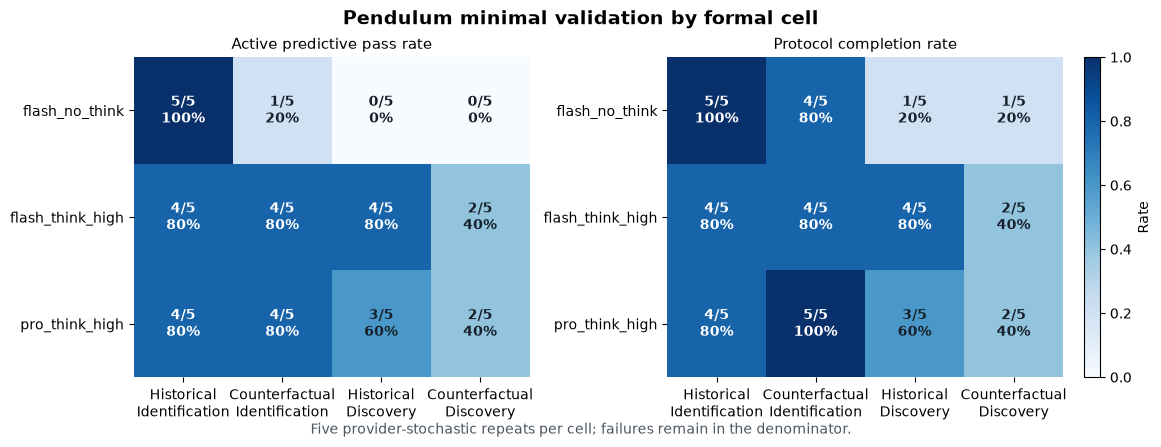

Saved: /Users/yushengzh/Workspace/RL/historyllm/role_benchmark/runs/pendulum_minimal_validation_20260824_v3/figures/pendulum_cell_rates.png


In [6]:
profile_order = ["flash_no_think", "flash_think_high", "pro_think_high"]
condition_order = [
    ("historical", "identification"),
    ("counterfactual", "identification"),
    ("historical", "discovery"),
    ("counterfactual", "discovery"),
]
condition_labels = [
    "Historical\nIdentification",
    "Counterfactual\nIdentification",
    "Historical\nDiscovery",
    "Counterfactual\nDiscovery",
]

def matrix_for(column):
    indexed = cell_summary.set_index(["player_profile", "world", "track"])
    return np.array([
        [indexed.loc[(profile, world, track), column] for world, track in condition_order]
        for profile in profile_order
    ], dtype=float)

pass_matrix = matrix_for("active_pass_rate")
completion_matrix = matrix_for("protocol_completion_rate")
pass_counts = matrix_for("active_passes").astype(int)
completion_counts = matrix_for("completed").astype(int)

plt.rcParams.update({"font.size": 10, "axes.titlesize": 11})
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2), constrained_layout=True)
for axis, matrix, counts, title in [
    (axes[0], pass_matrix, pass_counts, "Active predictive pass rate"),
    (axes[1], completion_matrix, completion_counts, "Protocol completion rate"),
]:
    image = axis.imshow(matrix, vmin=0, vmax=1, cmap="Blues", aspect="auto")
    axis.set_title(title)
    axis.set_xticks(range(len(condition_labels)), labels=condition_labels)
    axis.set_yticks(range(len(profile_order)), labels=profile_order)
    axis.tick_params(axis="x", labelrotation=0)
    for row_index in range(matrix.shape[0]):
        for column_index in range(matrix.shape[1]):
            value = matrix[row_index, column_index]
            color = "white" if value >= 0.62 else "#17212b"
            axis.text(
                column_index, row_index,
                f"{counts[row_index, column_index]}/5\n{value:.0%}",
                ha="center", va="center", color=color, fontweight="bold",
            )
    for spine in axis.spines.values():
        spine.set_visible(False)
colorbar = fig.colorbar(image, ax=axes, fraction=0.025, pad=0.02)
colorbar.set_label("Rate")
fig.suptitle("Pendulum minimal validation by formal cell", fontsize=14, fontweight="bold")
fig.text(
    0.5, -0.02,
    "Five provider-stochastic repeats per cell; failures remain in the denominator.",
    ha="center", color="#4a5560",
)
figure_path = FIGURE_DIR / "pendulum_cell_rates.png"
fig.savefig(figure_path, dpi=180, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {figure_path}")

### 7. Process metrics on completed episodes

In [7]:
completed_rows = episodes.loc[episodes["completed"]].copy()

def weighted_process(group):
    forecast_pairs = group["trajectory_scores.forecast_pair_count"].fillna(0)
    belief_pairs = group["trajectory_scores.scorable_belief_pair_count"].fillna(0)
    forecast_total = forecast_pairs.sum()
    belief_total = belief_pairs.sum()
    return pd.Series({
        "completed_episodes": len(group),
        "forecast_pairs": forecast_total,
        "pair_weighted_discriminativeness": (
            (group["trajectory_scores.experiment_discriminativeness_mean"].fillna(0) * forecast_pairs).sum()
            / forecast_total if forecast_total else np.nan
        ),
        "scorable_belief_pairs": belief_total,
        "pair_weighted_evidence_alignment": (
            (group["trajectory_scores.evidence_aligned_belief_update_rate"].fillna(0) * belief_pairs).sum()
            / belief_total if belief_total else np.nan
        ),
    })

process_summary = completed_rows.groupby(
    ["player_profile", "world", "track"], observed=True
).apply(weighted_process, include_groups=False).reset_index()
process_summary.to_csv(RUN_DIR / "process_summary_completed.csv", index=False)
display(process_summary.round(3))

print(
    "Process metrics exclude failed episodes because no committed final portfolio exists; "
    "their raw actions remain in JSONL and their omission is a known selection effect."
)

,player_profile,world,track,completed_episodes,forecast_pairs,pair_weighted_discriminativeness,scorable_belief_pairs,pair_weighted_evidence_alignment
0,flash_no_think,counterfactual,discovery,1.0,24.0,0.190,18.0,0.583
1,flash_no_think,counterfactual,identification,4.0,84.0,0.091,31.0,0.532
2,flash_no_think,historical,discovery,1.0,12.0,0.391,9.0,0.667
3,flash_no_think,historical,identification,5.0,99.0,0.066,42.0,0.714
4,flash_think_high,counterfactual,discovery,2.0,29.0,0.508,0.0,NaN
5,flash_think_high,counterfactual,identification,4.0,44.0,0.324,6.0,0.750
6,flash_think_high,historical,discovery,4.0,39.0,0.450,28.0,0.607
7,flash_think_high,historical,identification,4.0,32.0,0.379,5.0,0.800
8,pro_think_high,counterfactual,discovery,2.0,24.0,0.181,1.0,1.000
9,pro_think_high,counterfactual,identification,5.0,29.0,0.244,21.0,0.714


Process metrics exclude failed episodes because no committed final portfolio exists; their raw actions remain in JSONL and their omission is a known selection effect.


### 8. Observable model-call coverage and token use

In [8]:
call_summary = log_audit.groupby("player_profile", observed=True).agg(
    episodes=("episode_id", "size"),
    player_calls=("player_completions", "sum"),
    oracle_calls=("oracle_completions", "sum"),
    player_input_tokens=("player_input_tokens", "sum"),
    player_output_tokens=("player_output_tokens", "sum"),
    player_reasoning_tokens=("player_reasoning_tokens", "sum"),
    repair_calls=("repair_calls", "sum"),
    oracle_input_tokens=("oracle_input_tokens", "sum"),
    oracle_output_tokens=("oracle_output_tokens", "sum"),
).reset_index()
display(call_summary)
repair_view = episodes[["episode_id", "active_pass"]].merge(
    log_audit[["episode_id", "repair_calls"]], on="episode_id", how="left"
)
episodes_with_repair = int(repair_view["repair_calls"].gt(0).sum())
total_repairs = int(repair_view["repair_calls"].sum())
passes_with_repair = int(
    (repair_view["active_pass"].eq(1) & repair_view["repair_calls"].gt(0)).sum()
)
first_pass_active_pass = int(
    (repair_view["active_pass"].eq(1) & repair_view["repair_calls"].eq(0)).sum()
)
print(
    f"Logged raw public Player completions: {int(log_audit['player_completions'].sum())}; "
    f"logged Oracle presentation completions: {int(log_audit['oracle_completions'].sum())}."
)
print(
    f"Repair policy: {episodes_with_repair}/60 episodes used {total_repairs} repair calls; "
    f"{passes_with_repair}/33 passes used repair. Strict first-pass active pass: "
    f"{first_pass_active_pass}/60 ({first_pass_active_pass / 60:.1%})."
)

,player_profile,episodes,player_calls,oracle_calls,player_input_tokens,player_output_tokens,player_reasoning_tokens,repair_calls,oracle_input_tokens,oracle_output_tokens
0,flash_no_think,20,163,136,430742,51071,0,7,120420,2356
1,flash_think_high,20,101,67,226957,529894,501242,14,60227,1181
2,pro_think_high,20,76,41,157993,349418,322201,15,36787,724


Logged raw public Player completions: 340; logged Oracle presentation completions: 244.
Repair policy: 29/60 episodes used 36 repair calls; 14/33 passes used repair. Strict first-pass active pass: 19/60 (31.7%).


## Takeaways

1. **The simple Discovery advantage is not established.** On the full
   denominator, counterfactual Discovery passed 4/15 versus 9/15 for
   counterfactual Identification. The corresponding cell-level
   Discovery-minus-Identification contrasts are non-positive for all
   three profiles.
2. **A narrower prior-conflict effect is visible only without thinking.**
   Flash/non-thinking Identification falls from 5/5 in the historical
   world to 1/5 in the counterfactual world. Both thinking profiles are
   4/5 in each Identification world.
3. **Protocol attrition is the dominant confound.** Completion is
   26/30 for Identification but 13/30 for Discovery. Nine active episodes
   hit the 8192-token cap entirely in reasoning and returned empty visible
   JSON. Conditional pass rates therefore cannot be interpreted without
   the completion denominator.
4. **Repair policy changes the estimand.** Twenty-nine episodes invoked
   at least one logged repair (36 calls total), and 14/33 passes used
   repair. A strict first-pass sensitivity is 19/60 (31.7%).
5. **The current result is a diagnostic pilot.** It justifies the
   matched-world × track design, but a confirmatory run should first
   remove output-budget censoring and reduce Discovery representation
   failures, randomize/interleave the execution order, then freeze the
   protocol and use more than five repeats.
6. **No causal or model-ranking claim is warranted.** Repeats are
   provider-stochastic, sample sizes are small, and the three profiles
   represent only two base models plus one thinking-mode ablation.